# Chapitre 6 - Exercices 6.7 à 6.12

Validation croisée des polynômes locaux, densité jointe et Nadaraya-Watson, Bayes naïf
contre modèle additif logistique, critère $C_p$, dégénérescence de la vraisemblance des
mélanges gaussiens, analyse discriminante linéaire locale sur les chiffres manuscrits.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
from esl import datasets
from esl import ch06_noyaux as nk
set_style()
GREEN, YELLOW, RED = COLORS[2], COLORS[3], COLORS[7]
rng = np.random.RandomState(0)

## Exercice 6.7 : Validation croisée leave-one-out des polynômes locaux

**Énoncé.** Établir une expression de la somme des carrés des résidus de validation
croisée « leave-one-out » pour la régression polynomiale locale.

**Notations.** $\hat f(x_0) = \sum_j l_j(x_0)y_j$ est l'ajustement polynomial local (degré
$k$, largeur **métrique** $\lambda$) sur toutes les données, et $\hat f^{(-i)}(x_i)$
l'ajustement en $x_i$ obtenu **sans** l'observation $i$. On note
$S_{ii} = l_i(x_i)$ le $i$-ème terme diagonal de la matrice de lissage. On cherche
$$
\mathrm{CV} = \sum_{i=1}^N\big(y_i - \hat f^{(-i)}(x_i)\big)^2 .
$$

**Étape 1 : retirer $i$ = mettre son poids à zéro.** En la cible $x_i$, l'ajustement est
un problème de moindres carrés pondérés de poids $w_j = K_\lambda(x_i, x_j)$. Avec une
largeur métrique, retirer l'observation $i$ ne modifie pas les poids des autres
observations : $\hat f^{(-i)}(x_i)$ est la valeur en $x_i$ du polynôme $\hat P^{(-i)}$ qui
minimise $\sum_{j\ne i}w_j(y_j - P(x_j))^2$.

**Étape 2 : l'astuce de la réponse modifiée.** Remplaçons $y_i$ par
$y_i^* = \hat P^{(-i)}(x_i) = \hat f^{(-i)}(x_i)$ et gardons les autres $y_j$. Pour tout
polynôme $P$ :
$$
\sum_{j\ne i}w_j(y_j - P(x_j))^2 + w_i(y_i^* - P(x_i))^2 \ \ge\ \sum_{j\ne i}w_j(y_j - \hat P^{(-i)}(x_j))^2 + 0,
$$
et l'égalité a lieu pour $P = \hat P^{(-i)}$. Donc $\hat P^{(-i)}$ est aussi l'ajustement
**avec toutes les données** et la réponse $y^*$. Par linéarité :
$$
\hat f^{(-i)}(x_i) = \sum_{j\ne i}l_j(x_i)\,y_j + l_i(x_i)\,\hat f^{(-i)}(x_i)
= \hat f(x_i) - S_{ii}y_i + S_{ii}\hat f^{(-i)}(x_i).
$$

**Étape 3 : on résout.** Si $S_{ii}\ne 1$ :
$\hat f^{(-i)}(x_i) = \dfrac{\hat f(x_i) - S_{ii}y_i}{1 - S_{ii}}$, et donc
$$
y_i - \hat f^{(-i)}(x_i) = \frac{y_i - S_{ii}y_i - \hat f(x_i) + S_{ii}y_i}{1 - S_{ii}}
= \frac{y_i - \hat f(x_i)}{1 - S_{ii}},
\qquad
\boxed{\ \mathrm{CV} = \sum_{i=1}^N\left(\frac{y_i - \hat f(x_i)}{1 - S_{ii}}\right)^2\ }
$$
Un seul ajustement suffit : il faut les résidus ordinaires et la diagonale de $\mathbf S_\lambda$.

> **Remarque.** Avec une largeur des **k plus proches voisins**, retirer $x_i$ change la
> fenêtre en $x_i$ (il faut aller chercher un voisin de plus) : les poids des autres
> observations changent et la formule n'est plus qu'une **approximation**.

Vérification numérique : formule contre $N$ réajustements, pour une largeur métrique
(égalité exacte) et une largeur de k-ppv (approximation).

In [2]:
N = 100
x = np.sort(rng.uniform(0, 1, N))
y = np.sin(4 * x) + np.sqrt(1 / 3) * rng.normal(size=N)

def brute_cv(lam=None, k=None, degree=1):
    res = []
    for i in range(N):
        m = np.arange(N) != i
        kk = None if k is None else k
        res.append(y[i] - nk.local_regression(x[i:i + 1], x[m], y[m], lam=lam, k=kk,
                                              degree=degree, kernel="tricube")[0])
    return np.sum(np.array(res) ** 2)

for deg in (0, 1, 2):
    S = nk.smoother_matrix(x, lam=0.3, degree=deg, kernel="tricube")
    print("métrique, degré %d : formule = %.6f   réajustements = %.6f"
          % (deg, N * nk.loocv_error(S, y), brute_cv(lam=0.3, degree=deg)))
S = nk.smoother_matrix(x, k=30, degree=1, kernel="tricube")
print("30-ppv,   degré 1 : formule = %.6f   réajustements = %.6f"
      % (N * nk.loocv_error(S, y), brute_cv(k=30, degree=1)))

métrique, degré 0 : formule = 36.589829   réajustements = 36.589829
métrique, degré 1 : formule = 34.878172   réajustements = 34.878172
métrique, degré 2 : formule = 35.485491   réajustements = 35.485491
30-ppv,   degré 1 : formule = 35.777138   réajustements = 35.677039


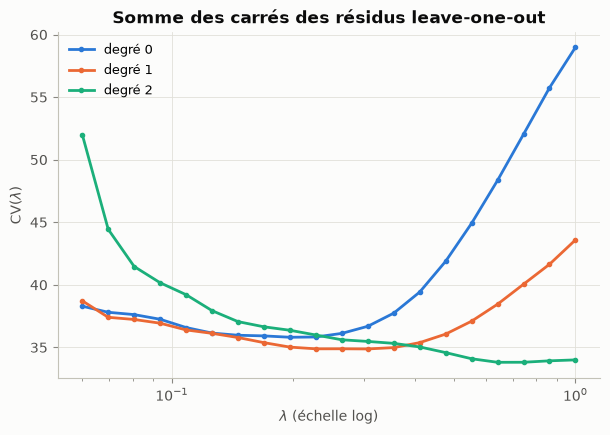

In [3]:
lams = np.geomspace(0.06, 1.0, 20)
fig = plt.figure(figsize=(7, 4.5))
for deg, c in zip((0, 1, 2), (BLUE, ORANGE, GREEN)):
    cvs = [N * nk.loocv_error(nk.smoother_matrix(x, lam=l, degree=deg, kernel="tricube"), y) for l in lams]
    plt.semilogx(lams, cvs, "o-", ms=3, color=c, label="degré %d" % deg)
plt.title("Somme des carrés des résidus leave-one-out")
plt.xlabel("$\\lambda$ (échelle log)"); plt.ylabel("CV($\\lambda$)"); plt.legend(); plt.show()

> **À retenir.** Pour tout lisseur obtenu par moindres carrés pondérés à poids fixes
> (polynômes locaux à largeur métrique), le résidu leave-one-out est le résidu ordinaire
> divisé par $1 - S_{ii}$ : la validation croisée ne coûte pas plus qu'un ajustement.

## Exercice 6.8 : Densité jointe par noyaux et Nadaraya-Watson

**Énoncé.** Pour une réponse continue $Y$ et un prédicteur $X$, on estime la densité jointe
de $(X, Y)$ par un estimateur à noyau gaussien bivarié, de noyau produit
$\varphi_\lambda(X)\varphi_\lambda(Y)$. Montrer que l'espérance conditionnelle
$\mathbb E(Y\mid X)$ déduite de cette estimation est un estimateur de Nadaraya-Watson.
Étendre ce résultat à la classification, en proposant un noyau adapté à l'estimation de la
loi jointe d'un $X$ continu et d'un $Y$ discret.

**Solution (cas continu).** L'estimateur de la densité jointe est
$$
\hat f(x, y) = \frac1N\sum_{i=1}^N\varphi_\lambda(x - x_i)\,\varphi_\lambda(y - y_i).
$$
- **Marge en $x$** : on intègre en $y$ ; comme $\int\varphi_\lambda(y - y_i)\,dy = 1$,
  $\hat f_X(x) = \int\hat f(x,y)\,dy = \frac1N\sum_i\varphi_\lambda(x - x_i)$.
- **Moment** : $\int y\,\varphi_\lambda(y - y_i)\,dy = y_i$ (espérance d'une
  $\mathcal N(y_i, \lambda^2)$), donc $\int y\hat f(x,y)\,dy = \frac1N\sum_i\varphi_\lambda(x - x_i)\,y_i$.
- **Espérance conditionnelle** :
$$
\hat{\mathbb E}(Y\mid X = x) = \frac{\int y\,\hat f(x,y)\,dy}{\hat f_X(x)}
= \frac{\sum_i\varphi_\lambda(x - x_i)\,y_i}{\sum_i\varphi_\lambda(x - x_i)},
$$
l'estimateur de Nadaraya-Watson (6.2) à noyau gaussien. La largeur en $y$ n'intervient pas
(seule compte la propriété « moyenne $y_i$ » du noyau en $y$).

Vérification par intégration numérique sur une grille fine en $y$ :

In [4]:
lam = 0.08
ygrid = np.linspace(y.min() - 3, y.max() + 3, 4001)
dy = ygrid[1] - ygrid[0]
for x0 in [0.1, 0.5, 0.9]:
    fxy = np.mean(norm.pdf(x0, x, lam)[:, None] * norm.pdf(ygrid[None, :], y[:, None], 0.5), axis=0)
    cond = np.sum(ygrid * fxy) * dy / (np.sum(fxy) * dy)
    print("x0 = %.1f : E(Y|X) par intégration = %.6f   Nadaraya-Watson = %.6f"
          % (x0, cond, nk.nadaraya_watson([x0], x, y, lam=lam, kernel="gaussian")[0]))

x0 = 0.1 : E(Y|X) par intégration = 0.653526   Nadaraya-Watson = 0.653526
x0 = 0.5 : E(Y|X) par intégration = 0.902472   Nadaraya-Watson = 0.902472
x0 = 0.9 : E(Y|X) par intégration = -0.393622   Nadaraya-Watson = -0.393622


**Extension à la classification.** Pour $G\in\{1,\dots,J\}$ discret, on remplace le noyau
en $y$ par un noyau **discret** sur les classes. Le plus simple est l'indicatrice
$K(g, g_i) = \mathbf 1(g = g_i)$ (une « masse de Dirac », qui somme à 1 sur les classes) :
$$
\hat f(x, g) = \frac1N\sum_i\varphi_\lambda(x - x_i)\,\mathbf 1(g_i = g),
\qquad
\hat\Pr(G = j\mid X = x) = \frac{\hat f(x, j)}{\sum_g\hat f(x, g)}
= \frac{\sum_i\varphi_\lambda(x - x_i)\mathbf 1(g_i = j)}{\sum_i\varphi_\lambda(x - x_i)} .
$$
C'est Nadaraya-Watson sur les indicatrices, et aussi la règle (6.25) avec
$\hat\pi_j = N_j/N$ et $\hat f_j$ l'estimateur de Parzen de la classe $j$ (même $\lambda$).

On peut aussi lisser en $g$ avec le noyau d'Aitchison-Aitken
$K_h(g, g_i) = 1 - h$ si $g = g_i$, $h/(J-1)$ sinon ($0\le h\le (J-1)/J$), qui somme
encore à 1 sur les classes. On obtient alors
$\hat\Pr_h(G = j\mid x) = (1 - h)\hat p_j(x) + \frac{h}{J-1}(1 - \hat p_j(x))$, où
$\hat p_j$ est la probabilité précédente : un **rétrécissement** vers la loi uniforme.

In [5]:
x3 = rng.uniform(0, 1, 200)
g3 = (x3 + 0.3 * rng.normal(size=200) > 0.5).astype(int) + (x3 > 0.8)
q = np.array([0.2, 0.5, 0.9])
post, cl = nk.kde_posterior(q, x3, g3, 0.1)
nw = np.column_stack([nk.nadaraya_watson(q, x3, (g3 == j).astype(float), lam=0.1, kernel="gaussian")
                      for j in cl])
print("écart max entre (6.25) et Nadaraya-Watson sur les indicatrices : %.2e" % np.max(np.abs(post - nw)))

écart max entre (6.25) et Nadaraya-Watson sur les indicatrices : 2.22e-16
